Today's topics:

* how a bitmap chart stores its data
* extracting data from a published figure with an AI assistant
* extracting data from a published figure with WebPlotDigitizer
* reading a file with no header row
* comparing extractions of the same curve

# Crushing a printed lattice

Today is a workshop day.
We will extract one curve from a published figure two ways.
An AI assistant will do it live, and we will do it by hand with WebPlotDigitizer.
Then we will compare both with my own extraction.

<img src="https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart.png" alt="Stress-strain curve of a printed lattice in compression, stress in MPa from 0 to 80 against strain from 0 to 0.8, drawn as a blue dashed line. The stress rises to a peak of about 45 MPa near strain 0.08, drops to about 4 MPa near 0.13, then wavers between about 10 and 20 MPa out to strain 0.65. Inset video frames show elastic deformation, shear band deformation, deformation, and the start of densification." width=540/>

*Figure 3 of Al-Saedi and Masood, "Mechanical performance of functionally graded lattice structures made with selective laser melting 3D printing," IOP Conf. Ser.: Mater. Sci. Eng. 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), [CC BY 3.0](https://creativecommons.org/licenses/by/3.0/).*

Above: An aluminum-silicon (AlSi12) lattice, printed by selective laser melting and crushed in compression.

Lattices like this can absorb energy in a crash.

First the struts bend.
Then a band of cells collapses.
The rest crush at a fairly steady stress.
Near a strain of 0.6 the struts start to touch and the lattice densifies.

The paper contains only the picture.
To analyze the curve, we need its numbers.

# How a chart stores its data

## Vector and bitmap

A figure is saved in one of two ways.

* A **vector** figure (PDF, SVG) stores shapes: the coordinates of each line and the text of each label.
* A **bitmap** figure (PNG, JPG) stores a grid of pixels, each with a color.

Our figure is a bitmap.
The numbers behind the curve are gone.
Only colored pixels remain.

Let's load the figure in Python and look at it as data:

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import urllib.request  # downloads a file

chart_url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart.png'
urllib.request.urlretrieve(chart_url, 'digitizing_chart.png')  # saves a copy in Colab

image = plt.imread('digitizing_chart.png')
print(image.shape)  # rows, columns, color values

(559, 733, 4)


The image is a NumPy array with one entry per pixel.
Each pixel holds four numbers from 0 to 1: red, green, blue, and opacity.

`imshow` draws the array:

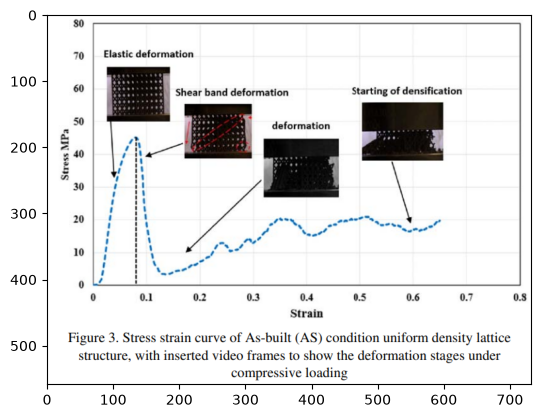

In [2]:
fig, ax = plt.subplots()
ax.imshow(image)  # the axes count pixels, not strain and stress

The axes now count pixel columns and rows.
Rows count down from the top.

## From pixels to numbers

To read numbers off the chart we need two things:

1. **Which pixels belong to the curve.**
   Here, the blue ones.
2. **How pixels map to data values.**
   On a linear axis, two tick marks with known values are enough.
   This is **axis calibration**.

For strain, if column $c_0$ sits at the tick for 0 and column $c_1$ at the tick for 0.8:

$$\text{strain} = 0.8 \times \frac{c - c_0}{c_1 - c_0}$$

Stress works the same way with rows and the ticks for 0 and 80 MPa.
On a log axis, the same formula applies to the logarithm of the value.

One pixel column crosses the curve at one height.
So each column gives one row of the CSV.

Both of today's tools follow these steps.
The AI assistant writes code to do them.
In WebPlotDigitizer we do the calibration by hand.

# Extracting the curve with AI Studio

I will run this part live in [Penn State AI Studio](https://ai.psu.edu/ai-services/ai-studio).

Before uploading a figure to an AI tool, check its license.
This one is CC BY 3.0.
Anyone may copy and share it, with credit to the authors.

## What to tell the assistant

* which model: one that can run code
* what the figure is: a compressive stress-strain curve
* the axes: strain from 0 to 0.8 and stress from 0 to 80 MPa, both linear
* which curve: the blue dashed line
* what to ignore: the black dashed vertical line, the arrows, the inset photos, and the text
* how: run code on the image, rather than reading values by eye
* what to return: a plot of the extracted points on the same axes, and the points as a CSV file with two columns and no header row

## Reading the tool calls

AI Studio shows each tool call: the Python code the model wrote and what it printed.
Look for the steps from the bitmap section:

* where the code opens the image
* how it decides which pixels are blue
* where it turns pixel columns and rows into strain and stress
* how it picks one value per column

A tool call with no errors shows that the code ran.
The points can still be off.
If the code puts an axis end at the wrong pixel, every point shifts.

### [Check your understanding]

Compare the assistant's plot with the original figure:

* the axes: 0 to 0.8 in strain, 0 to 80 MPa in stress
* the peak, about 45 MPa near a strain of 0.08
* the sharp drop to about 4 MPa near 0.13
* the plateau, wavering between about 10 and 20 MPa
* the end, about 20 MPa near a strain of 0.65
* no column of points at 0.08 from the black dashed line

Which of these could the assistant get wrong while its code still runs without errors?

# Extracting the curve with WebPlotDigitizer

[WebPlotDigitizer](https://apps.automeris.io/wpd4/) is a free tool that runs in the browser.
We click the calibration ticks ourselves.

## Load the image

1. Save the figure to your computer from [this link](https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart.png).
2. Open [WebPlotDigitizer](https://apps.automeris.io/wpd4/).
3. **File** -> **Load Image(s)** -> select the figure.

## Calibrate the axes

1. Choose **2D (X-Y) Plot** -> **Align Axes**.
2. Click four tick marks, in this order:
   * strain 0 on the x axis
   * strain 0.8 on the x axis
   * stress 0 on the y axis
   * stress 80 on the y axis

   The zoom box in the corner helps you hit each tick.
   The arrow keys nudge a point after you click it.
3. **Complete** -> type in the values 0, 0.8, 0, and 80.
   Both axes are linear, so leave **Log scale** unchecked.
   Then click **OK**.

## Pick the curve

The **Automatic Extraction** panel is on the right.

1. **Foreground Color** (the colored box) -> **Color Picker** -> click on a blue dash -> **Done**.
2. **Mask** -> **Box** -> drag a box around the blue curve.
   Leave out the inset photos.
3. **Distance** -> 80 -> **Filter Colors**.
   Distance sets how close a color must be to the blue.
   The pixels that pass are highlighted in yellow.

## Run the extraction

1. Choose **Averaging Window** -> 6 Px, 6 Px -> **Run**.
   Red dots appear on top of the blue line.
2. Look at the red dots.
   Do they follow the peak, the drop, and the plateau?
   If they miss the line, change Distance or the window and run again.

## Save the points

1. **View Data** opens the points as text.
2. **Download .CSV** saves them as a file.
   The file has no header row.
3. In Colab, click the folder icon on the left and drag the file into the Files pane.

Colab deletes uploaded files when the session resets, so keep your copy.

# Comparing three extractions

## My extraction

I also extracted this curve with WebPlotDigitizer.
It is our **reference**: another reading of the same picture, not the true curve.

Here are its first lines:

```
0.0051296043656207,-0.0278107426590423
0.0137981710858671,1.2326194453430477
0.0175132711088298,3.5303549529721465
```

There is no header row with column names.
Let's see what `pandas` does with that:

In [3]:
url = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart_wpd.csv'
print(pd.read_csv(url).columns)

Index(['0.0051296043656207', '-0.0278107426590423'], dtype='str')


`pandas` used the first row of numbers as the column names.
That point is now missing from the data.

With `header=None`, every row is read as data.
`names=` gives the columns their names:

In [4]:
reference = pd.read_csv(url, header=None, names=['strain', 'stress_MPa'])
display(reference)

,strain,stress_MPa
0,0.005130,-0.027811
1,0.013798,1.232619
2,0.017513,3.530355
3,0.019990,6.064491
4,0.021848,8.378969
...,...,...
88,0.613168,16.667244
89,0.621836,17.093648
90,0.631743,17.803953
91,0.641650,18.879144


The first stress is slightly negative.
That small error can come from calibrating the axes on the image.

## Your two extractions

Change each file name below to the name of your file in the Files pane.
Until you do, the cell reads two stand-ins:

* a WebPlotDigitizer extraction from last year's class
* a test of the same hints in another AI assistant (OpenAI Codex), run on November 20, 2026

In [5]:
wpd_file = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart_wpd_2025.csv'  # your WebPlotDigitizer CSV
ai_file = 'https://raw.githubusercontent.com/wfreinhart/matse219/main/datasets/digitizing_chart_ai_test.csv'  # the AI Studio CSV

wpd = pd.read_csv(wpd_file, header=None, names=['strain', 'stress_MPa'])
ai = pd.read_csv(ai_file, header=None, names=['strain', 'stress_MPa'])

Let's put all three on one plot, with the same limits as the figure:

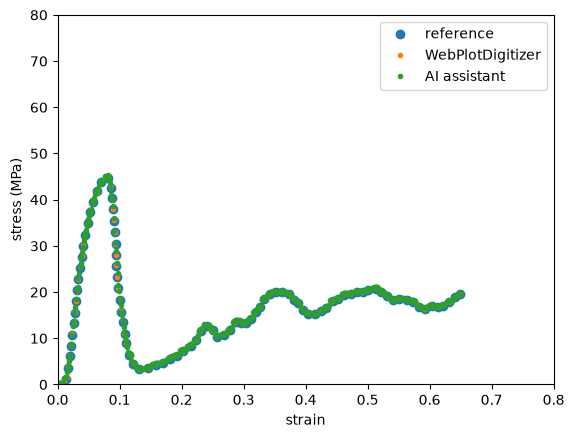

In [6]:
fig, ax = plt.subplots()
ax.plot(reference['strain'], reference['stress_MPa'], 'o', label='reference')
ax.plot(wpd['strain'], wpd['stress_MPa'], '.', label='WebPlotDigitizer')
ax.plot(ai['strain'], ai['stress_MPa'], '.', label='AI assistant')
ax.set_xlim(0, 0.8)
ax.set_ylim(0, 80)
ax.set_xlabel('strain')
ax.set_ylabel('stress (MPa)')
ax.legend()

Do the three follow the same curve?
Let's compare a few numbers:

In [7]:
print(len(reference), len(wpd), len(ai))  # number of points
print(reference['stress_MPa'].max(), wpd['stress_MPa'].max(), ai['stress_MPa'].max())  # peak stress
print(reference['strain'].max(), wpd['strain'].max(), ai['strain'].max())  # last strain

93 94 517
44.74580372969161 44.84785994484128 45.2525
0.6484610916753341 0.6486470824138562 0.6502


### [Check your understanding]

All three extractions read the same picture.

1. Why can two extractions of the same curve have very different numbers of points?
2. How far apart are the three peak stresses?
   Which step of the extraction could move the peak?
3. Copy the plotting cell into the empty cell below and change its strain limits to `ax.set_xlim(0.05, 0.15)`.
   Where do the extractions disagree most?

# Summary

* A bitmap chart stores pixels, not numbers. Axis calibration maps pixel columns and rows to data values.
* WebPlotDigitizer: calibrate the axes by hand, pick the curve's color, and run the extraction.
* An AI assistant can write and run the same extraction code. Read its tool calls and check its result against the figure.
* `pd.read_csv(url, header=None, names=[...])` reads a file with no header row.
* Compare extractions of the same curve by point count, peak, and end point.

## Further reading

* Penn State, [AI Studio](https://ai.psu.edu/ai-services/ai-studio)
* WebPlotDigitizer, [user manual](https://automeris.io/docs/)
* NumPy, [`numpy.interp`](https://numpy.org/doc/stable/reference/generated/numpy.interp.html)

# Appendix A: more on WebPlotDigitizer

A few cases our figure did not need:

* If an axis is logarithmic, check **Log scale** when you type in the axis values.
* For a series drawn as separate markers, check that the extraction has one point per marker.

The tool measures pixels on the image.
The numbers are only as accurate as the picture and our clicks.

For an AI assistant, the same calibration goes into the request.
Say which axes are logarithmic and give two labeled tick values on each.

# Appendix B: Energy under the curve

Homework 12 uses `np.interp` from this appendix.

The energy absorbed per unit volume is the area under the stress-strain curve.
Stress in MPa times strain gives MJ/m$^3$.
Let's estimate it up to a strain of 0.6 from the reference.

In [8]:
strain = reference['strain']
stress = reference['stress_MPa']

## A first estimate

The area under a curve is its average height times its width.

Let's average the reference stress of every point up to a strain of 0.6:

In [9]:
before_dense = strain <= 0.6
print(np.mean(stress[before_dense]) * 0.6)  # MJ/m^3

11.012309812361117


About 11 MJ/m$^3$.

But look at the reference points on the plot.
They are concentrated on the steep rise and drop around the peak.
How many sit below a strain of 0.1?

In [10]:
print(np.sum(strain < 0.1))  # True counts as 1

31


A third of the points sit near the peak, where the stress is highest.
In a plain mean, the peak region gets too much weight.

We want the stress at evenly spaced strains instead.
Most of those strains fall between our points.

## Interpolation between two points

What is the stress at a strain of 0.253?
Here are the reference points around it:

In [11]:
display(reference[(strain > 0.24) & (strain < 0.27)])

,strain,stress_MPa
48,0.241038,12.755100
49,0.250326,11.752414
50,0.257756,10.334012
51,0.268902,10.720074


**Linear interpolation** estimates the value from a straight line between the two neighbors.

`np.interp(x_new, x, y)` does this for us.
The known `x` values must be in increasing order.

In [12]:
print(np.interp(0.253, strain, stress))  # MPa

11.241995109018898


11.24 MPa sits between the stresses of its two neighbors, as it should.

## On an even grid

`np.interp` also takes an array of new `x` values.

Let's make 61 evenly spaced strains from 0 to 0.6 and interpolate the stress at each:

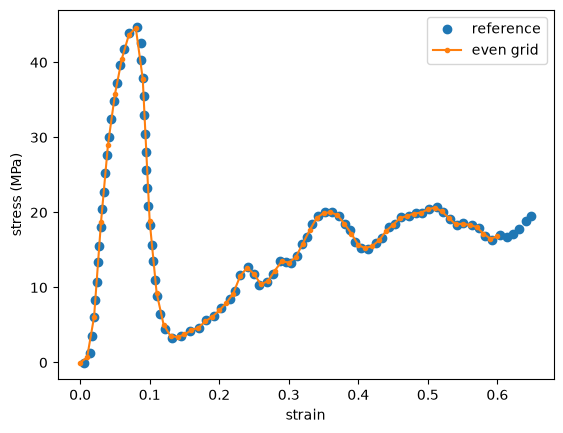

In [13]:
strain_grid = np.linspace(0, 0.6, 61)  # steps of 0.01
stress_grid = np.interp(strain_grid, strain, stress)

fig, ax = plt.subplots()
ax.plot(strain, stress, 'o', label='reference')
ax.plot(strain_grid, stress_grid, '.-', label='even grid')
ax.set_xlabel('strain')
ax.set_ylabel('stress (MPa)')
ax.legend()

Now every strain counts equally.
Let's repeat the energy estimate with the grid:

In [14]:
print(np.mean(stress_grid) * 0.6)  # MJ/m^3

9.684245450710163


About 9.7 MJ/m$^3$, 12% less than the plain mean.

So up to a strain of 0.6, this lattice absorbs about 10 MJ per cubic meter: 9.7 from the reference.

## Plateau stress

The **plateau stress** is the average stress while the cells crush, here between strains 0.2 and 0.6.

1. Compute it from the reference points between 0.2 and 0.6.
   The mask `plateau` below selects them.
2. Compute it again from 41 evenly spaced strains between 0.2 and 0.6, using `np.interp`.

How different are the first two?
Why did the grid change the energy estimate but not this one?

In [15]:
plateau = (strain >= 0.2) & (strain <= 0.6)

## Outside the data

The reference stops at a strain of 0.648.
What does `np.interp` give at 0.7?

In [16]:
print(np.interp(0.7, strain, stress))
print(stress.iloc[-1])  # the last reference point

19.528383165937136
19.528383165937136


Outside the data, `np.interp` returns the value at the nearest end.
It gives no error and no warning.

But at 0.7 the lattice is densifying.
Its stress climbs as the struts pack together.
The real stress is likely higher than 19.5 MPa, and we have no points there to check.

Estimating between our points is **interpolation**.
Beyond the last point it is **extrapolation**.

# Appendix C: A figure for a report

## Checking a figure

Check a figure against the numbers, not against how it looks:

* **Units.** Each axis names its quantity and units: strain has none, stress is in MPa.
* **Scale.** The stress spans about 0 to 45 MPa, so a linear axis works.
* **Limits.** Compare the axis limits with the smallest and largest values we printed.
  No point should fall outside the axes.
* **Point count.** The figure should show every row of the CSV.

## Writing the caption

A caption says what is plotted, where the data came from, and how the figure was made.
Here is one for a figure of an AI extraction:

> **Figure 1.** Compressive stress-strain curve of an as-built AlSi12 lattice made by selective laser melting.
> Points extracted from Figure 3 of Al-Saedi and Masood, *IOP Conf. Ser.: Mater. Sci. Eng.* 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), CC BY 3.0.
> Extraction code written and run by [model name] in Penn State AI Studio on November 20, 2026.
> Plotting code written and run by [model name] in Penn State AI Studio on November 20, 2026.
> We checked the axes, peak, drop, plateau, and end point against the original figure.

Replace `[model name]` with the full name of the model.

If you used the reference, the source lines change:

> **Figure 1.** Compressive stress-strain curve of an as-built AlSi12 lattice made by selective laser melting.
> Points digitized with WebPlotDigitizer from Figure 3 of Al-Saedi and Masood, *IOP Conf. Ser.: Mater. Sci. Eng.* 433, 012078 (2018), [doi:10.1088/1757-899X/433/1/012078](https://doi.org/10.1088/1757-899X/433/1/012078), CC BY 3.0.
> Plotting code written and run by [model name] in Penn State AI Studio on November 20, 2026.

Here the authors measured the curve themselves.
When the data in a figure come from another paper, the caption cites both papers.

# Appendix D: from stress back to strain

At what strain does the lattice first reach 30 MPa?

Swapping the arguments, `np.interp(30, stress, strain)`, would need the stresses in increasing order.
They rise to the peak and then fall.
So we keep only the points up to the peak:

In [17]:
peak = np.argmax(stress)  # position of the highest stress
rising = strain <= strain[peak]  # up to and including the peak
print(np.interp(30, stress[rising], strain[rising]))

0.04106250490396169


A strain of about 0.041, on the rising part of the curve before the peak.

# Appendix E: What is an AI agent?

If time remains, we will watch an agent do the same task.

## From a tool call to an agent

In Lecture 33 we saw a **tool call**: the model's output is a request to search or run code.
The app runs the request and adds the result to the model's input.

An **AI agent** uses a model to choose actions, call tools, inspect their results, and choose the next action toward a goal.

One tool call alone does not demonstrate this feedback loop.
The loop does:

1. **Goal:** our request.
2. **Action:** the model chooses a tool call, such as running code or saving a file.
3. **Result:** the app runs the tool and adds its output to the model's input.
4. **Next action:** with that result in its input, the model chooses another action, or stops.

Steps 2 to 4 repeat until the model stops.

In AI Studio today, we were part of this loop.
We checked the extraction against the figure.
An agent can choose and run checks, then use their results to choose a repair or stop.

The loop is what counts, whatever the product is called.
A chat app can run this loop.
A coding tool can also give one reply with no loop.

## A live demo

I will run a coding agent on my laptop, in a folder that holds only the figure, `digitizing_chart.png`.
The agent can read files, run Python, and write files in that folder.

Here is the whole task as one request:

```
This folder holds digitizing_chart.png: Figure 3 of a paper, the compressive stress-strain curve of a 3D-printed metal lattice.
The x axis is strain, linear, from 0 to 0.8.
The y axis is stress in MPa, linear, from 0 to 80.

1. Extract the blue dashed curve as numbers by running code on the image.
   Ignore the black dashed vertical line, the arrows, the inset photos, and all text.
   Save the points as extraction.csv, sorted by strain, with no header row and two columns: strain, then stress in MPa.
2. Check the extraction against the figure: plot your points on top of the image and compare the peak, the drop after it, the plateau, and the end.
   Save the overlay as extraction_overlay.png, open it with an image-viewing tool, and inspect it before deciding whether to continue or revise the extraction.
   If a check fails, find the cause, fix the code, and check again.
3. Compute the energy absorbed per unit volume up to a strain of 0.6, in MJ/m^3:
   the stress from numpy's np.interp at 61 evenly spaced strains from 0 to 0.6, then the mean of those, times 0.6.
4. Make a publication-quality figure of stress against strain from the same points and save it as lattice_figure.png.

When all four are done, list each check, what it showed, and anything you changed.
If you cannot complete a check, report what remains unresolved.
```

While it runs, write down one example of each:

* **Action.** Which tool did it call? What file or result did that produce?
* **Feedback.** Which result did it inspect? What did it do differently next?
  A failed check is the clearest case.
* **Stopping and oversight.** Why did it stop? What can we check without relying on its report?

Look for the model using a tool result to choose its next action.
A script and a final reply alone do not show that decision.

## Checking the agent's work

* **Energy.** The request pinned our method.
  Compare with the approximate reference estimate, 9.7 MJ/m$^3$.
  A difference may come from the extraction; recomputing from the agent's CSV checks its arithmetic separately.
* **Figure.** Apply the same checklist: units, scale, limits, point count.
* **Checks.** Open the files it wrote and look for the overlay of its points on the figure.
  A sentence in the reply is not a check.

The person who reports the number is responsible for it.
The caption names the agent, the model, and the date.